# YOLO26n — kết quả Colab và đánh giá lại đúng ID

**Trần Xuân Bắc — 2A202603132 — L2A.**

[Phiên Colab đã train](https://colab.research.google.com/drive/1YR1tewJQCXHockB095uWxlC7hF9NdBQC) đủ 50 epoch trên 50 ảnh student; 10 ảnh eval tách riêng. Notebook gốc có output được giữ tại `notebooks/day2_colab_executed_original.ipynb`.

Phiên Colab mở từ bản notebook cũ, chưa chuyển raw ID eval `0 car, 1 van, 2 truck, 3 bus` về ID student/model `0 car, 1 truck, 2 bus, 3 van`. Sau khi nhận checkpoint, đã chấm lại CPU local bằng bản sao eval đúng ID. Giữ nguyên file nguồn, box và split.

Notebook này hiển thị artifact thật của **train Colab + đánh giá lại local**, không chạy lại train hoặc giả lập một phiên Colab mới. `last.pt` epoch 50 được chọn giữa hai checkpoint còn lưu; không khẳng định best xuyên suốt mọi epoch trung gian.

In [1]:
from pathlib import Path
import json
import csv
import subprocess
import sys
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'tools/evaluate_colab_checkpoint.py').is_file() and (ROOT.parent / 'tools/evaluate_colab_checkpoint.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'tools/evaluate_colab_checkpoint.py').is_file():
    target = Path('/content/Day2-Colab-Results') if Path('/content').is_dir() else ROOT / 'Day2-Colab-Results'
    if not target.exists():
        subprocess.run(['git', 'clone', 'https://github.com/trxuanbac/K5-L2A-DAY02-TranXuanBac-2A202603132-ObjectDetection', str(target)], check=True)
    ROOT = target
ASSETS = ROOT / 'report/individual/assets'
m = json.loads((ASSETS / 'model_eval_metrics.json').read_text())
raw = json.loads((ASSETS / 'model_eval_metrics_colab_original.json').read_text())
assert m['experiment'] == 'student_colab_corrected_eval' and m['epochs_completed'] == 50
assert m['eval_images'] == 10 and m['train_images'] == 50
print('Train: Google Colab; re-evaluation:', m['evaluation_environment'])
print('Selected checkpoint:', m['checkpoint_name'], 'epoch:', m['checkpoint_epoch'])
print('Checkpoint SHA-256:', m['checkpoint_sha256'])


Train: Google Colab; re-evaluation: local CPU; weights trained in Google Colab
Selected checkpoint: last.pt epoch: 50
Checkpoint SHA-256: 205846fb44de0e33f8bafe2863108341a357e7e3301e4e686d0b6b09fa99cac5


In [2]:
rows = ['| Evaluation | Precision | Recall | mAP50 | mAP50–95 |', '|---|---:|---:|---:|---:|']
rows.append(f"| Original Colab, IDs mismatched | {raw['precision']:.6f} | {raw['recall']:.6f} | {raw['map50']:.6f} | {raw['map50_95']:.6f} |")
for c in m['candidates']:
    rows.append(f"| Correct IDs: {c['checkpoint_name']} | {c['precision']:.6f} | {c['recall']:.6f} | {c['map50']:.6f} | {c['map50_95']:.6f} |")
display(Markdown('\n'.join(rows)))
rows = ['| Class | Precision | Recall | mAP50 | mAP50–95 |', '|---|---:|---:|---:|---:|---:|']
for name, v in m['per_class'].items():
    rows.append(f"| {name} | {v['precision']:.4f} | {v['recall']:.4f} | {v['map50']:.4f} | {v['map50_95']:.4f} |")
display(Markdown('\n'.join(rows)))
print('Selection limitation:', m['selection_limitation'])


| Evaluation | Precision | Recall | mAP50 | mAP50–95 |
|---|---:|---:|---:|---:|
| Original Colab, IDs mismatched | 0.463981 | 0.238666 | 0.276521 | 0.205533 |
| Correct IDs: best.pt | 0.366920 | 0.365905 | 0.390364 | 0.251436 |
| Correct IDs: last.pt | 0.578292 | 0.600400 | 0.566441 | 0.353671 |

| Class | Precision | Recall | mAP50 | mAP50–95 |
|---|---:|---:|---:|---:|---:|
| car | 0.8672 | 0.8404 | 0.8911 | 0.5683 |
| truck | 0.2741 | 0.4112 | 0.1928 | 0.1349 |
| bus | 0.8506 | 0.7500 | 0.8332 | 0.4466 |
| van | 0.3213 | 0.4000 | 0.3486 | 0.2648 |

Selection limitation: Intermediate epoch checkpoints were not saved; this does not establish the best corrected score across all 50 epochs.


## Log train Colab

CSV có đúng 50 epoch. Các đường validation trong đồ thị gốc dùng raw ID chưa khớp; giữ chúng làm lịch sử, không trình bày như validation đã sửa.

Training rows: 50 epochs 1–50


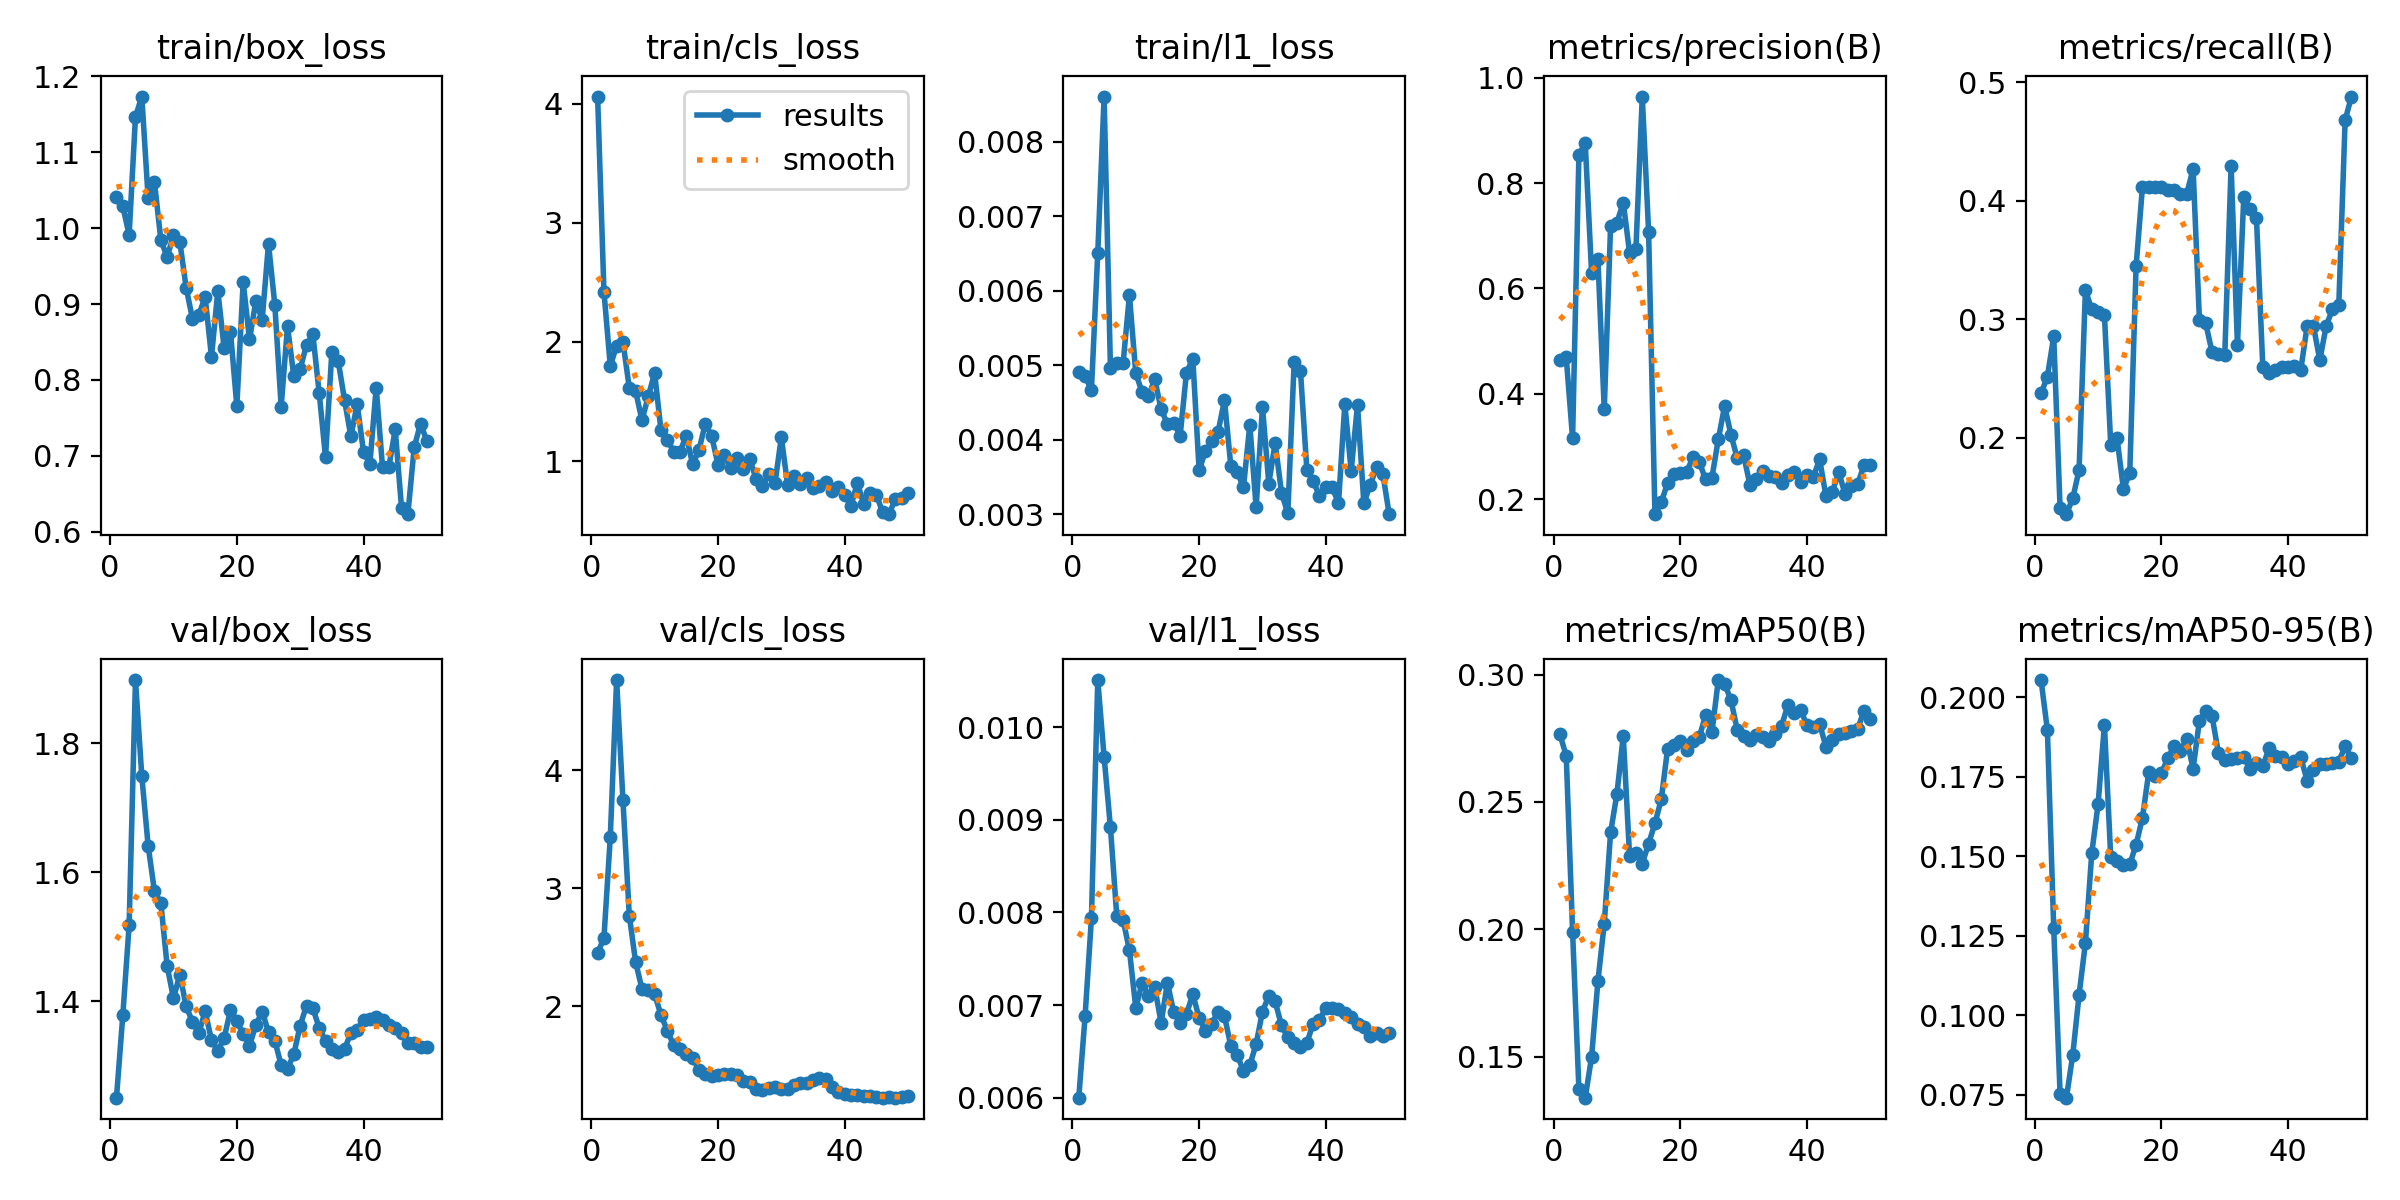

In [3]:
train_dir = ASSETS / m['published_train_dir']
with (train_dir / 'results.csv').open() as f:
    training_rows = list(csv.DictReader(f))
assert [int(float(r['epoch'])) for r in training_rows] == list(range(1, 51))
print('Training rows:', len(training_rows), 'epochs 1–50')
display(Image(filename=str(train_dir / 'results.png')))


## Validation sau chuẩn hóa ID

Các hình dưới đây từ checkpoint được chọn, chấm lại local trên đúng 10 ảnh eval. Confusion matrix dùng ngưỡng riêng của validator; khác đếm minh họa prediction tại confidence 0,25.

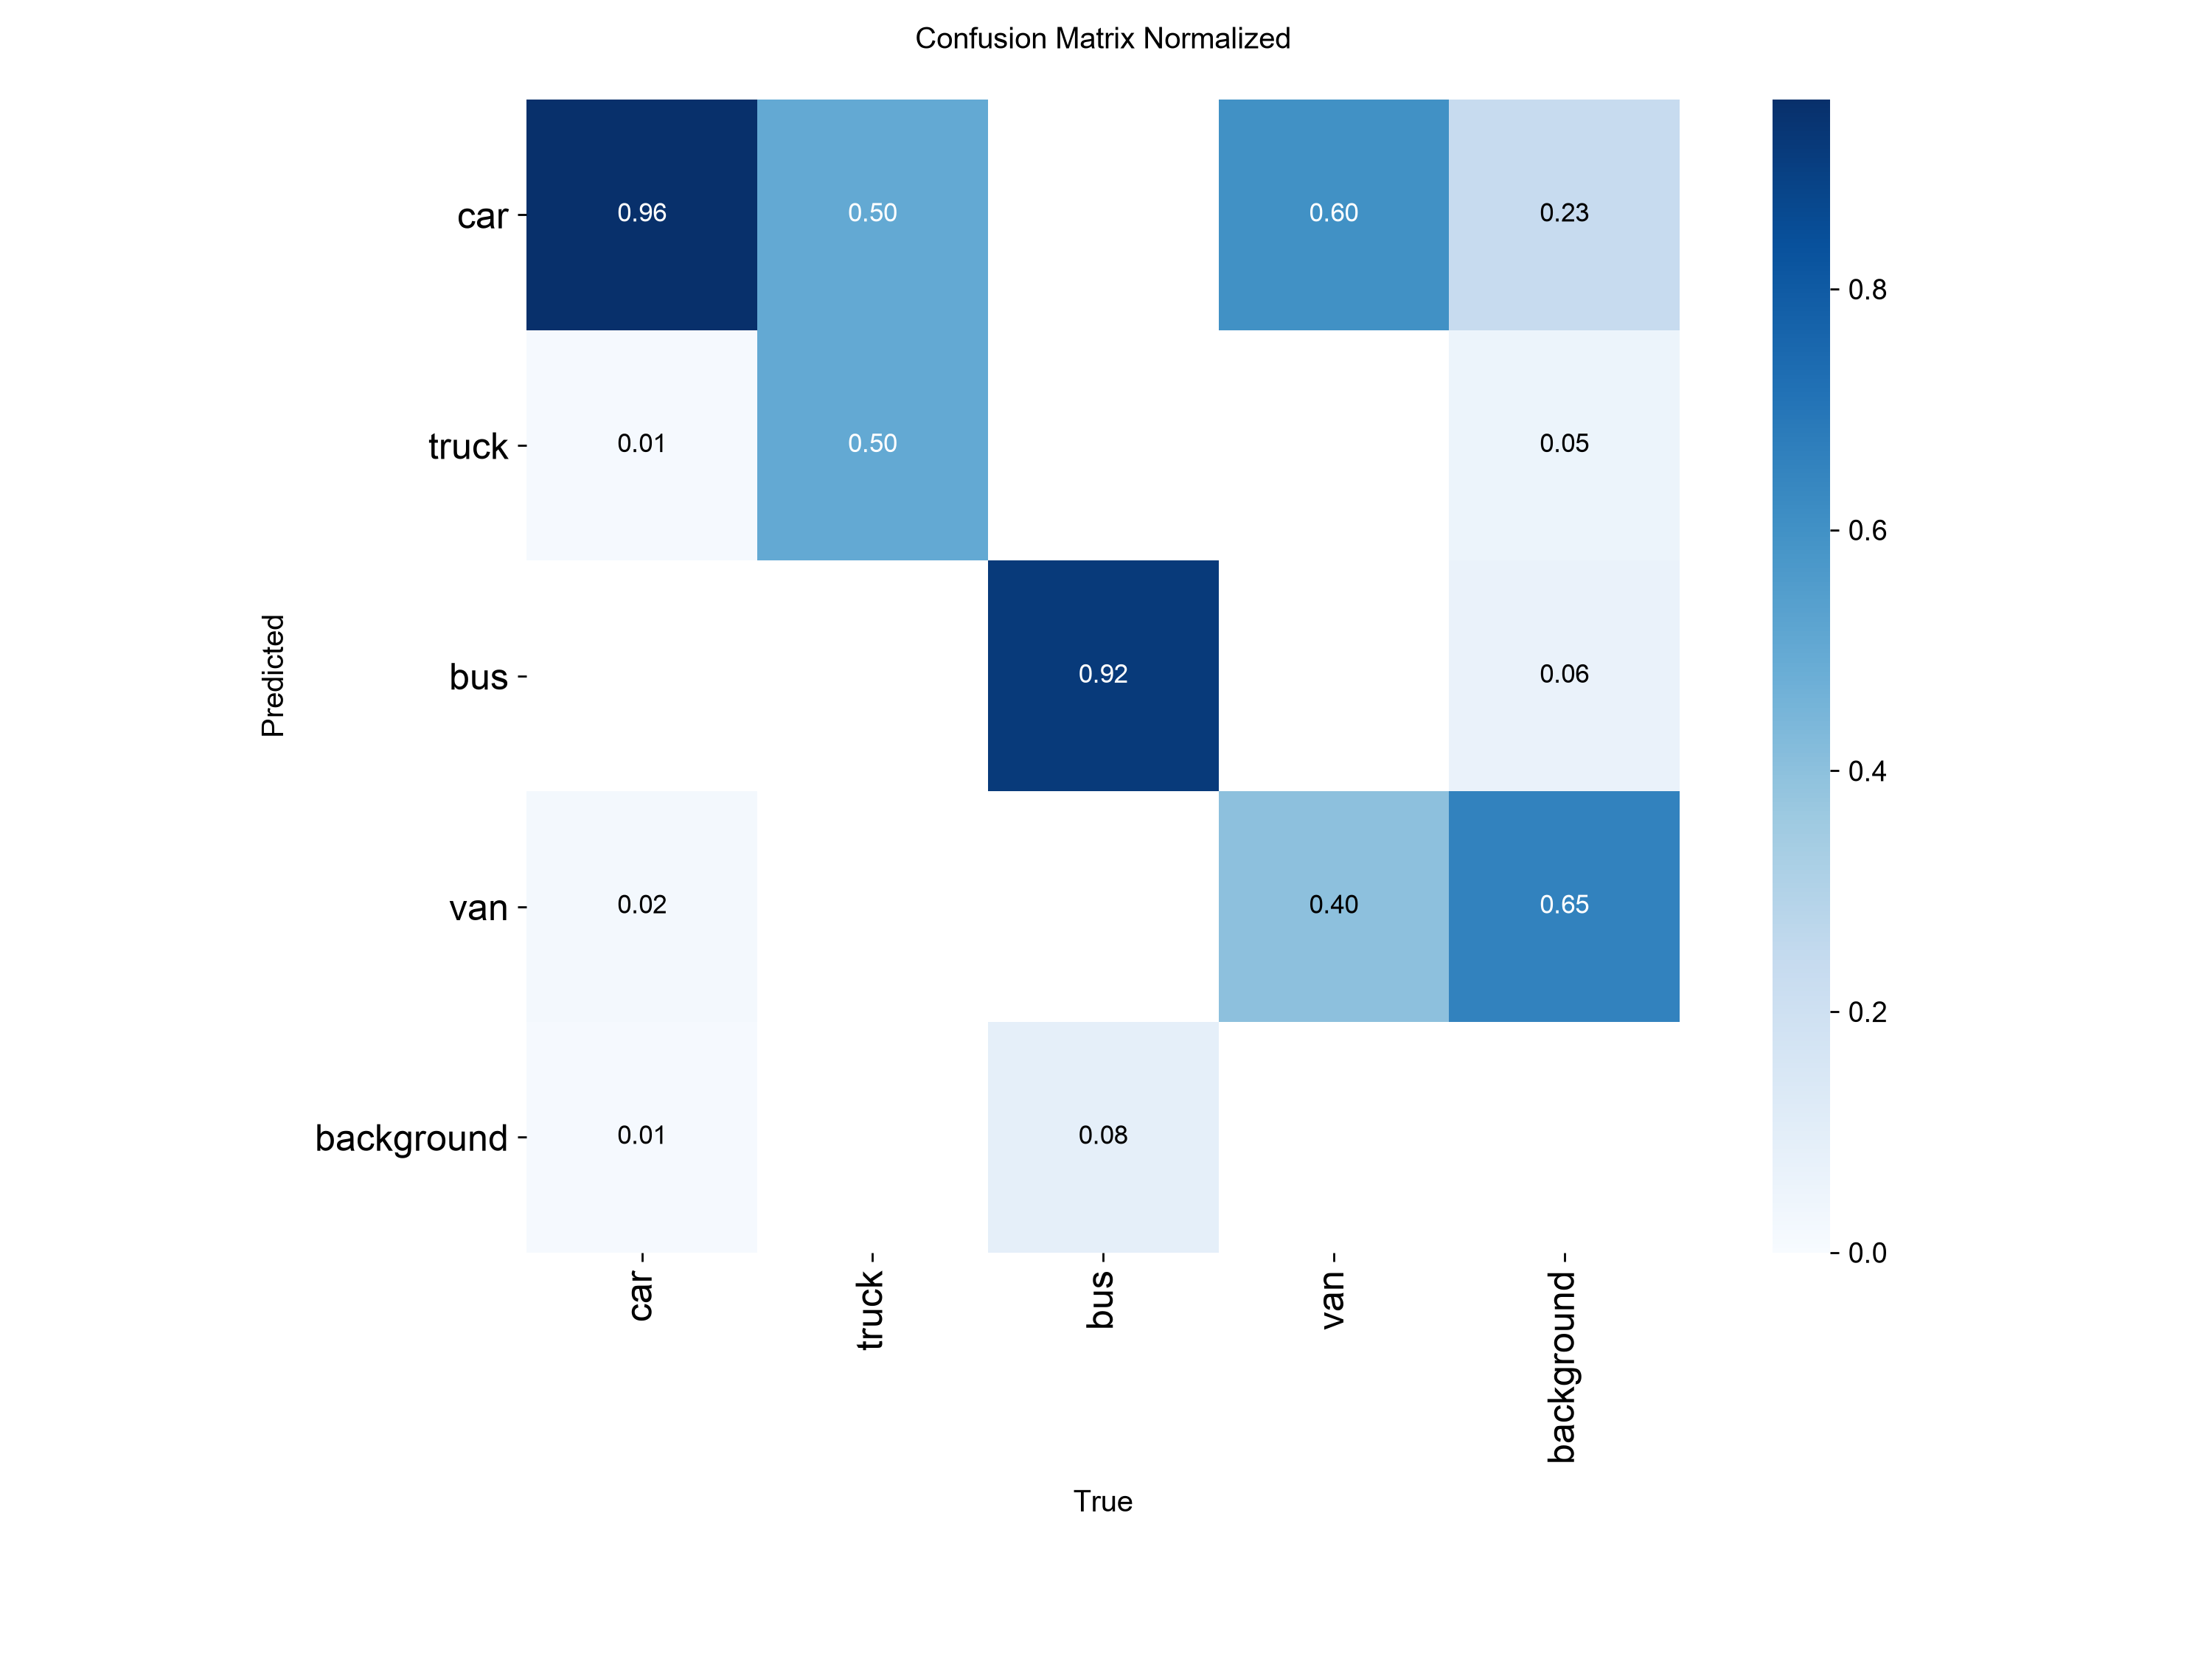

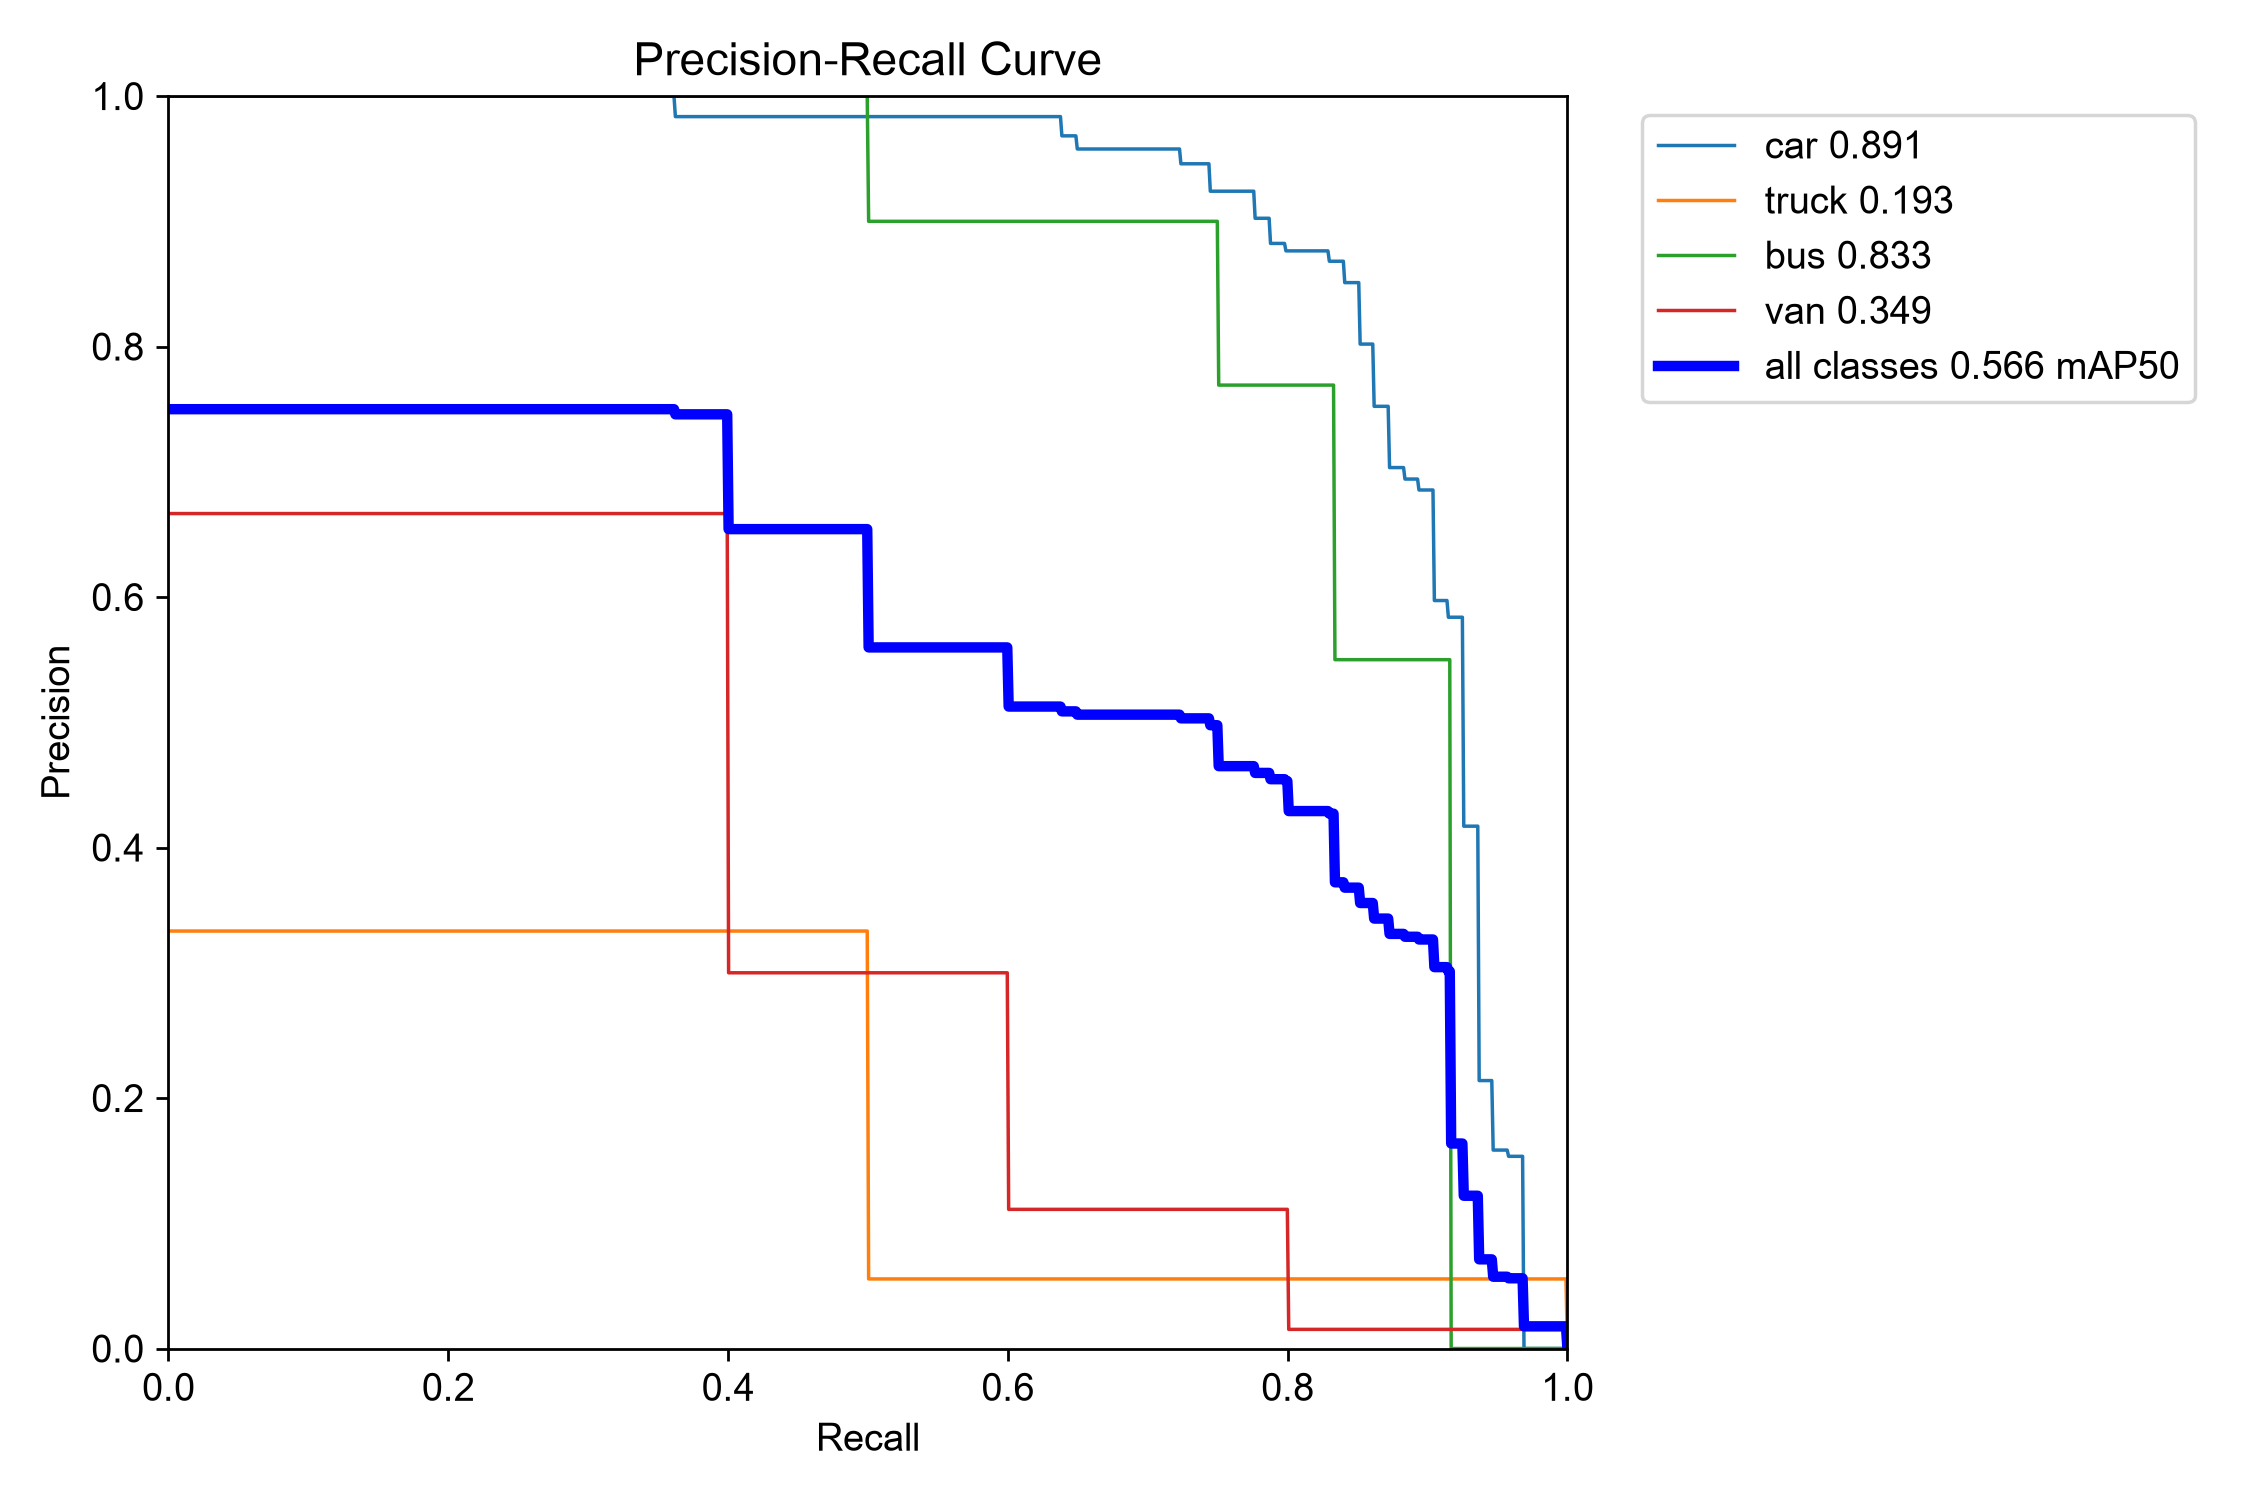

In [4]:
eval_dir = ASSETS / m['published_eval_dir']
display(Image(filename=str(eval_dir / 'confusion_matrix_normalized.png')))
display(Image(filename=str(eval_dir / 'BoxPR_curve.png')))


## 10 ảnh prediction của checkpoint được chọn

Matplotlib is building the font cache; this may take a moment.


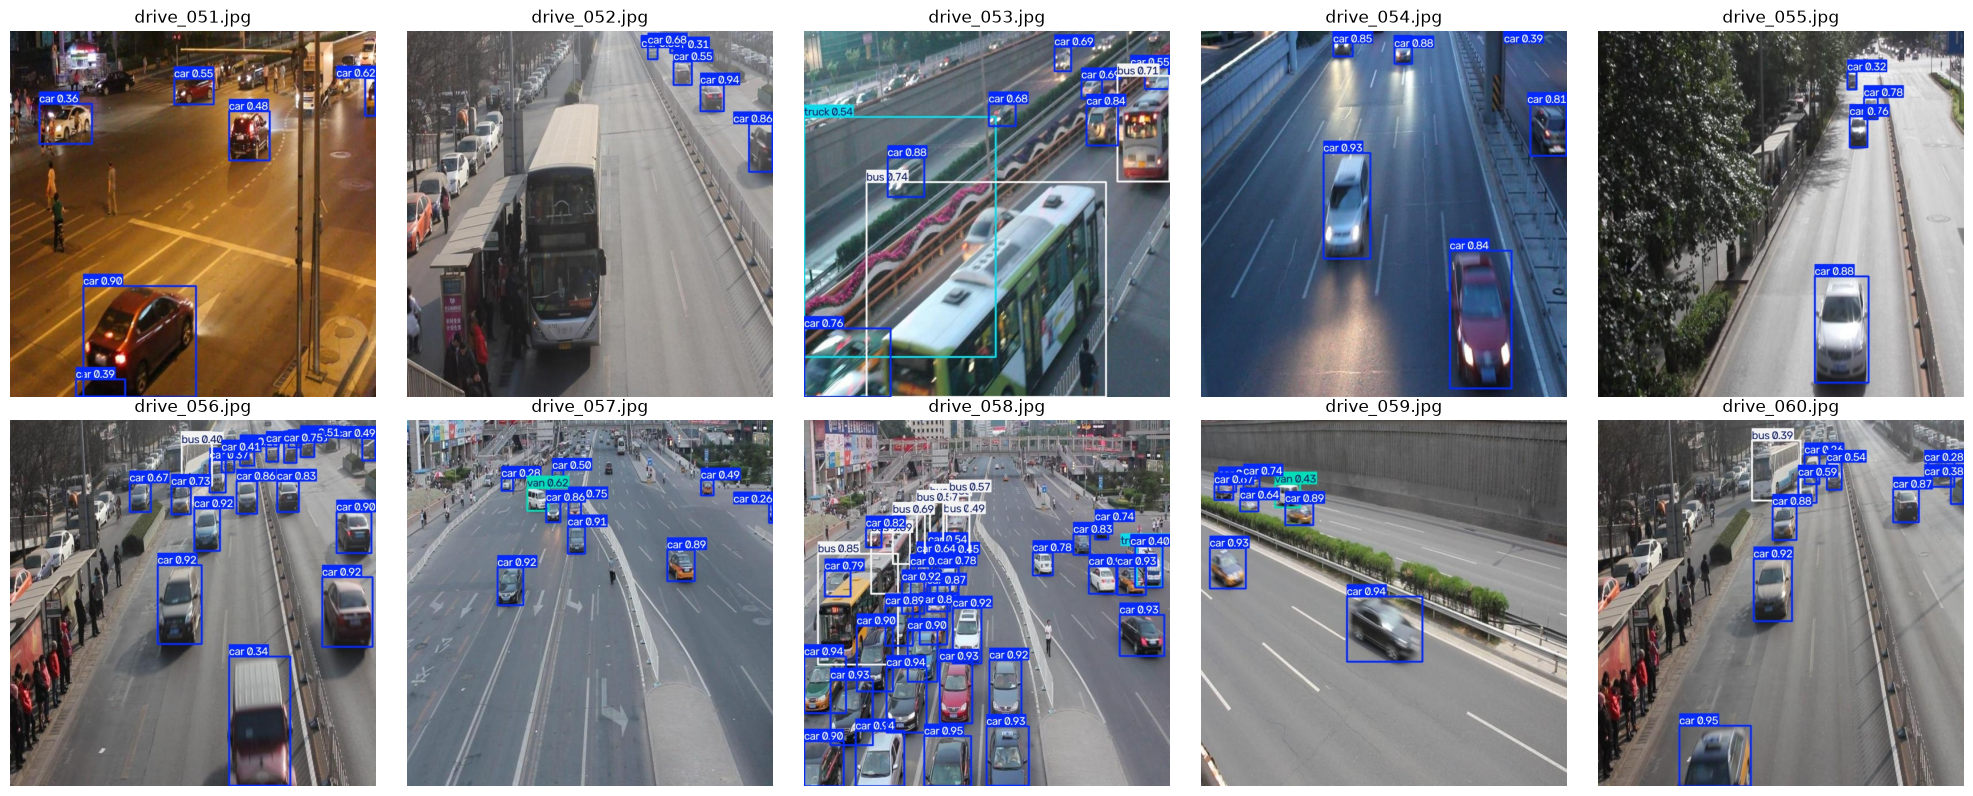

In [5]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage
images = sorted((ASSETS / m['published_prediction_dir']).glob('*.jpg'))
assert len(images) == 10
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, image in zip(axes.flat, images):
    ax.imshow(PILImage.open(image))
    ax.set_title(image.name)
    ax.axis('off')
plt.tight_layout()
plt.show()


In [6]:
a = json.loads((ASSETS / 'student_prediction_analysis.json').read_text())
assert a['checkpoint_sha256'] == m['checkpoint_sha256']
lowest = a['lowest_validation_recall_class']
print('Lowest validation recall:', lowest, a['lowest_validation_recall'])
print('Illustration:', a['illustration']['image'], a['illustration']['classes'][lowest])
print('Wrong-class examples:', [(r['image'], r['expected'], r['predicted'], r['iou']) for r in a['wrong_class_examples']])
print('Matched boxes with IoU < 0.75:', a['matches_iou_below_075'], '/', a['matched_boxes'])
print('mAP50 - mAP50–95:', m['map50'] - m['map50_95'])


Lowest validation recall: van 0.4
Illustration: drive_053.jpg {'truth': 1, 'predictions': 0, 'tp': 0, 'fn': 1, 'fp': 0}
Wrong-class examples: [('drive_052.jpg', 'van', 'car', 0.8866), ('drive_053.jpg', 'van', 'car', 0.8608), ('drive_056.jpg', 'van', 'car', 0.8517), ('drive_060.jpg', 'van', 'car', 0.823)]
Matched boxes with IoU < 0.75: 20 / 93
mAP50 - mAP50–95: 0.21277071985354856


## Trả lời bốn câu hỏi theo kết quả đã sửa

1. **Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa.** Với checkpoint `last.pt` đã chấm đúng schema, **van thấp nhất, recall = 0,4000**; truck = 0,4112, bus = 0,7500 và car = 0,8404. Trong [drive_053.jpg](../report/individual/assets/eval_predictions/visuals/drive_053.jpg), van trắng ở phần đường bên trái bị nhận thành car; box dự đoán khớp box eval với IoU **0,8608**. Ở confidence 0,25, ảnh có 1 van theo eval, 0 dự đoán van, 1 FN van. Đây là minh họa ở một confidence, khác recall validation được tổng hợp theo đường cong.
2. **Nếu mAP50 cao nhưng mAP50–95 thấp, box đang gặp vấn đề gì?** Phiên chấm lại có **mAP50 = 0,5664**, **mAP50–95 = 0,3537**, chênh **0,2128**. Khi tăng yêu cầu IoU, box lệch hoặc lấy thừa/thiếu thân xe mất điểm. Cần kiểm bốn cạnh box, nhất là xe bị che, xe nhỏ và cắt khung. Chẩn đoán ở confidence 0,25 có **93** cặp cùng lớp khớp IoU ≥ 0,50, trong đó **20** cặp có IoU < 0,75. Chênh lệch mAP gợi ý chất lượng định vị cần cải thiện; tự nó không chứng minh annotation train sai.
3. **Có lỗi truck/bus/van/car nào liên quan tới guideline không?** Đã thấy **van → car** trên `drive_052` (IoU 0,8866), `drive_053` (0,8608), `drive_056` (0,8517), `drive_060` (0,8230). Các ca có box khá sát nhưng sai lớp, nên cần rà tính nhất quán khi phân biệt MPV nhỏ với van thân hộp theo guideline. Train có car 490, truck 20, bus 53, van 44, là dữ liệu ít và mất cân bằng; chưa có thí nghiệm tách nguyên nhân để kết luận lỗi chỉ do guideline. Lỗi thứ tự ID eval là lỗi pipeline riêng, giải thích vì sao bảng Colab cũ hiển thị bus recall 0%; không dùng bảng đó để suy ra model không nhận được bus. Không sửa gold/eval để làm tăng điểm.
4. **Vì sao không dùng 10 ảnh eval để train dù chúng có nhãn?** Giữ chúng tách khỏi train để đo khả năng khái quát trên ảnh model chưa học trực tiếp. Train rồi chấm trên chính các ảnh đó gây rò rỉ dữ liệu và làm điểm quá lạc quan. Eval còn được dùng làm validation/chọn checkpoint, kể cả việc so hai checkpoint đã lưu ở đây, nên **không phải test set độc lập**. Giữ nguyên 50 train/10 eval.

## Chấm lại khi còn checkpoint trong runtime

Mặc định chỉ hiển thị kết quả đã lưu. Có thể đặt `RERUN_EVALUATION=True` trong runtime Colab còn thư mục `/content/Day2-Lab/outputs` để đánh giá lại hai checkpoint. Đây là thao tác val/predict, không train lại. Cần Ultralytics 8.4.208 và PyYAML. Không upload gold train hoặc checkpoint lên GitHub.

In [7]:
RERUN_EVALUATION = False
CHECKPOINT_SOURCE = Path('/content/Day2-Lab/outputs') if Path('/content/Day2-Lab/outputs').is_dir() else ROOT / 'outputs/colab_import/original'
if RERUN_EVALUATION:
    assert (CHECKPOINT_SOURCE / 'yolo26_runs/vehicle_annotation/weights/last.pt').is_file()
    subprocess.run([sys.executable, str(ROOT / 'tools/evaluate_colab_checkpoint.py'),
                    '--source', str(CHECKPOINT_SOURCE), '--root', str(ROOT)], cwd=ROOT, check=True)
    print('New eval artifacts:', ROOT / 'outputs/colab_import/corrected')
else:
    print('Displayed saved results; no training or evaluation rerun in this notebook execution.')


Displayed saved results; no training or evaluation rerun in this notebook execution.


## Giới hạn và nguồn bằng chứng

- Chỉ có `best.pt` và `last.pt`; không khôi phục được best theo eval đúng ID trong mọi epoch trung gian.
- Eval dùng chọn checkpoint, không phải test set độc lập. Các chỉ số có thể dao động khi chỉ có 2 truck và 5 van trong eval.
- Notebook Colab gốc và ZIP được kiểm tra SHA-256 trong `assets/colab_import_manifest.json`. Không thay output của notebook gốc.
- Phần sửa pipeline, đánh giá checkpoint và soạn câu trả lời có Codex hỗ trợ; xem báo cáo cá nhân.
